Homework 6, problem 2, part c

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

# Parameters
eta = 0.02
N = 400_000
x_star, y_star = 8 / 17, 9 / 17
P_make = np.array([[0.40, 0.60], [0.40, 0.25]])
pts_val = np.array([2.0, 3.0])

In [2]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def K_func(x, y):

    def antideriv(s, s_star):
        return (1 - 2 * s_star) * np.log(s / (1 - s)) - s_star / s- (1 - s_star) / (1 - s)
        
    return (
        antideriv(x, x_star)
        - antideriv(x_star, x_star)
        + antideriv(y, y_star)
        - antideriv(y_star, y_star)
    )

In [3]:
# part i
def ode_rhs(t, state):
    x, y = state
    dx = 0.85 * eta * (x * (1 - x)) ** 2 * (y - y_star)
    dy = -0.85 * eta * (y * (1 - y)) ** 2 * (x - x_star)
    return [dx, dy]

sol = solve_ivp(ode_rhs, [0, 5000], [0.2, 0.3], rtol=1e-11, atol=1e-13, dense_output=True)
t_eval = np.linspace(0, 5000, 50000)
x_ode, y_ode = sol.sol(t_eval)
K_ode = K_func(x_ode, y_ode)

print('mean flow orbit')
print(f'x range: [{x_ode.min():.4f}, {x_ode.max():.4f}]')
print(f'y range: [{y_ode.min():.4f}, {y_ode.max():.4f}]')
print(f'K variation (max - min): {K_ode.max() - K_ode.min():.2e}')

mean flow orbit
x range: [0.1628, 0.8082]
y range: [0.3000, 0.8372]
K variation (max - min): 4.62e-01


In [4]:
# part ii
def simulate(tau, seed=42):
    rng = np.random.default_rng(seed)
    th1, th2 = 0.3, -0.3
    b = 0.0  # Running-average baseline
    xs = np.empty(N)
    ys = np.empty(N)

    # Pre-draw uniform random numbers for speed
    u_a1 = rng.random(N)
    u_a2 = rng.random(N)
    u_shot = rng.random(N)

    for t in range(N):
        x = 1.0 / (1.0 + np.exp(-th1))
        y = 1.0 / (1.0 + np.exp(-th2))
        xs[t], ys[t] = x, y

        a1 = 1 if u_a1[t] < x else 0  # 1: shoot 3, 0: shoot 2
        a2 = 1 if u_a2[t] < y else 0  # 1: D2, 0: D3
        col = 0 if a2 == 1 else 1  # matrix col 0 is D2, col 1 is D3

        made = 1.0 if u_shot[t] < P_make[a1, col] else 0.0
        pts = pts_val[a1] * made

        # Running-average baseline update
        b += (pts - b) / (t + 1)

        # Policy gradient + entropy bonus updates
        th1 += eta * ((pts - b) * (a1 - x) - tau * th1 * x * (1.0 - x))
        th2 += eta * ((-pts + b) * (a2 - y) - tau * th2 * y * (1.0 - y))

    dists = np.sqrt((xs - x_star) ** 2 + (ys - y_star) ** 2)
    return xs, ys, dists

In [5]:
# part ii
results = {}
for tau in [0.0, 0.05]:
    xs, ys, dists = simulate(tau)
    results[tau] = (xs, ys, dists)
    print(f'tau = {tau}:')
    print(
        f'- Last-quarter avg (x, y) = ({xs[-100_000:].mean():.4f},'
        f'{ys[-100_000:].mean():.4f})'
    )
    print(f'- Early mean dist (first 50k) = {dists[:50_000].mean():.4f}')
    print(f'- Late mean dist (last 50k) = {dists[-50_000:].mean():.4f}')

tau = 0.0:
- Last-quarter avg (x, y) = (0.4697,0.4877)
- Early mean dist (first 50k) = 0.4306
- Late mean dist (last 50k) = 0.6389
tau = 0.05:
- Last-quarter avg (x, y) = (0.4604,0.5196)
- Early mean dist (first 50k) = 0.1959
- Late mean dist (last 50k) = 0.1715


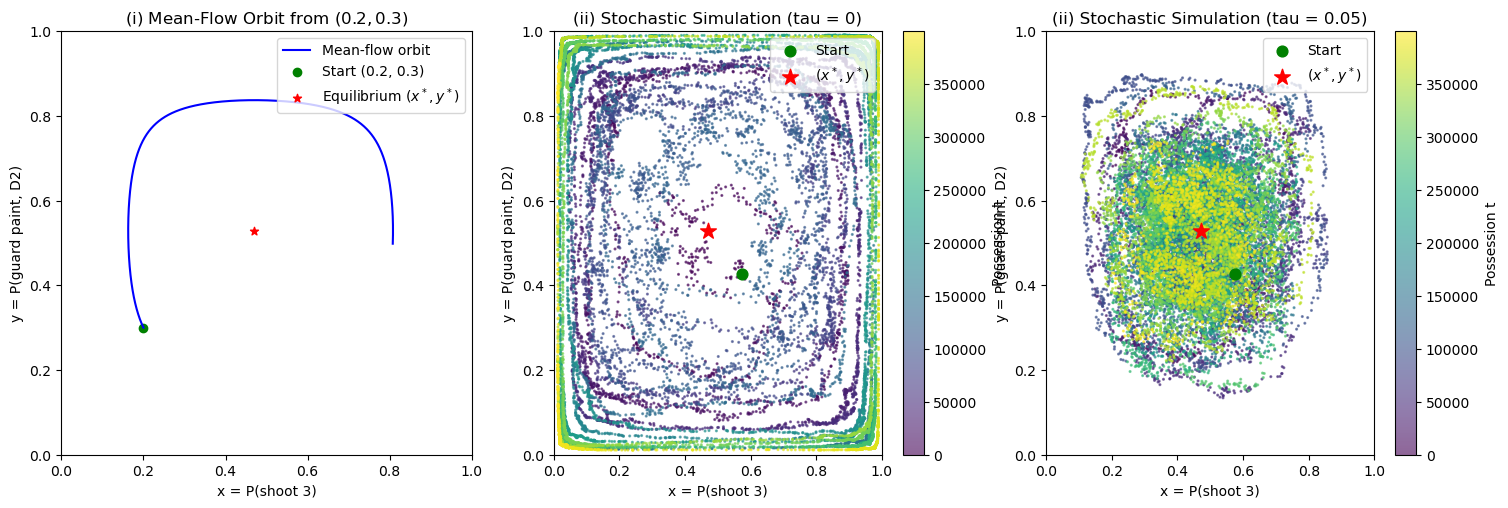

In [6]:
# plotting
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5))

# plot 1
ax1.plot(x_ode, y_ode, color = 'blue', label = 'Mean-flow orbit')
ax1.scatter([0.2], [0.3], color = 'green', label = 'Start (0.2, 0.3)')
ax1.scatter([x_star], [y_star], color = 'red', marker = '*', label = 'Equilibrium $(x^*, y^*)$',
)
ax1.set_title('(i) Mean-Flow Orbit from $(0.2, 0.3)$')
ax1.set_xlabel('x = P(shoot 3)')
ax1.set_ylabel('y = P(guard paint, D2)')
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.legend(loc = 'upper right')

step = 20
t_idx = np.arange(0, N, step)

# plot 2
xs_0, ys_0, _ = results[0.0]
sc2 = ax2.scatter(xs_0[::step], ys_0[::step], c = t_idx, cmap = 'viridis', s = 1.5, alpha = 0.6, rasterized = True)
ax2.scatter([xs_0.item(0)], [ys_0.item(0)], color = 'green', s = 60, zorder = 5, label = 'Start')
ax2.scatter([x_star], [y_star], color = 'red', marker = '*', s = 140, zorder = 6, label = '$(x^*, y^*)$',)
ax2.set_title('(ii) Stochastic Simulation (tau = 0)')
ax2.set_xlabel('x = P(shoot 3)')
ax2.set_ylabel('y = P(guard paint, D2)')
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.legend(loc = 'upper right')
plt.colorbar(sc2, ax = ax2, label='Possession t')

# plot 3
xs_05, ys_05, _ = results[0.05]
sc3 = ax3.scatter(xs_05[::step], ys_05[::step], c = t_idx, cmap = 'viridis', s = 1.5, alpha = 0.6, rasterized = True,)
ax3.scatter([xs_05.item(0)], [ys_05.item(0)], color = 'green', s = 60, zorder = 5, label = 'Start')
ax3.scatter([x_star], [y_star], color='red', marker = '*', s = 140, zorder = 6, label = '$(x^*, y^*)$',)
ax3.set_title('(ii) Stochastic Simulation (tau = 0.05)')
ax3.set_xlabel('x = P(shoot 3)')
ax3.set_ylabel('y = P(guard paint, D2)')
ax3.set_xlim(0, 1)
ax3.set_ylim(0, 1)
ax3.legend(loc = 'upper right')
plt.colorbar(sc3, ax = ax3, label = 'Possession t')

plt.show()